<a href="https://colab.research.google.com/github/sashwatrj/urban_heat_mapping/blob/main/DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [87]:
import pandas as pd

df = pd.read_csv('/content/Bhubaneswar_ML_Dataset_2024.csv')

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:")
print(df.columns.tolist())

Dataset loaded successfully!
Rows: 50076
Columns:
['system:index', 'LST_Celsius', 'NDBI', 'NDVI', 'NDWI', '.geo']


In [88]:
# Keep only the variables we need for machine learning

df_ml = df[['NDVI', 'NDBI', 'NDWI', 'LST_Celsius']].copy()

# Check for missing values
print("Missing values:")
print(df_ml.isnull().sum())

# Show basic statistics
print("\nDataset statistics:")
print(df_ml.describe())

Missing values:
NDVI           0
NDBI           0
NDWI           0
LST_Celsius    0
dtype: int64

Dataset statistics:
               NDVI          NDBI          NDWI   LST_Celsius
count  50076.000000  50076.000000  50076.000000  50076.000000
mean       0.478587     -0.027828     -0.454119     37.494421
std        0.121352      0.104523      0.081855      1.937994
min       -0.007251     -0.583819     -0.737958     29.076418
25%        0.395218     -0.090472     -0.507697     36.326040
50%        0.471926     -0.013589     -0.457108     37.464240
75%        0.563216      0.047529     -0.407442     38.640038
max        0.866741      0.330093      0.114119     47.660194


In [89]:
# Step 11: Prepare data for Machine Learning

from sklearn.model_selection import train_test_split

# Input variables (features)
X = df_ml[['NDVI', 'NDBI', 'NDWI']]

# Target variable
y = df_ml['LST_Celsius']

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Features (X):
       NDVI      NDBI      NDWI
0  0.224880  0.174705 -0.336342
1  0.231342  0.164992 -0.344287
2  0.376398  0.022909 -0.413823
3  0.496667 -0.133460 -0.462954
4  0.514238 -0.084604 -0.474451

Target (y):
0    43.021940
1    44.119125
2    39.627846
3    36.059433
4    36.578970
Name: LST_Celsius, dtype: float64

Shape of X: (50076, 3)
Shape of y: (50076,)

Training samples: 40060
Testing samples: 10016


In [90]:
# Step 12: Train Random Forest Regression model

from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [91]:
# Step 15: Calculate UHI intensity

import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Load the predicted LST raster again
input_file = "/content/Bhubaneswar_Predicted_LST_2024.tif"

with rasterio.open(input_file) as src:
    predicted_LST = src.read(1).astype(float)

    # Read NoData value
    nodata = src.nodata

# Convert NoData pixels to NaN
if nodata is not None:
    predicted_LST[predicted_LST == nodata] = np.nan

# Calculate mean LST
mean_lst = np.nanmean(predicted_LST)

print("Mean predicted LST:", round(mean_lst, 2), "°C")

# Calculate UHI intensity
uhi = predicted_LST - mean_lst

print("Minimum UHI:", round(np.nanmin(uhi), 2), "°C")
print("Maximum UHI:", round(np.nanmax(uhi), 2), "°C")

Mean predicted LST: 37.49 °C
Minimum UHI: -8.14 °C
Maximum UHI: 9.7 °C


In [92]:
# Step 16: Save UHI intensity as a GeoTIFF

import rasterio

input_file = "/content/Bhubaneswar_Predicted_LST_2024.tif"
output_file = "/content/Bhubaneswar_UHI_2024.tif"

# Open the original predicted LST raster to copy its map information
with rasterio.open(input_file) as src:
    profile = src.profile.copy()

# Update raster settings for UHI output
profile.update(
    dtype="float32",
    count=1,
    nodata=-9999
)

# Replace NaN with NoData value
uhi_output = np.where(np.isnan(uhi), -9999, uhi).astype("float32")

# Save UHI raster
with rasterio.open(output_file, "w", **profile) as dst:
    dst.write(uhi_output, 1)

print("UHI GeoTIFF created successfully!")
print("File:", output_file)


UHI GeoTIFF created successfully!
File: /content/Bhubaneswar_UHI_2024.tif


In [93]:
# ============================================
# DEEP LEARNING - CNN MODEL
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("CNN section started successfully!")

CNN section started successfully!


In [94]:
# ============================================
# STEP 2: LOAD SATELLITE RESEARCH RASTER
# ============================================

import rasterio

raster_file = "/content/Bhubaneswar_Research_Raster_2024.tif"

with rasterio.open(raster_file) as src:
    raster_data = src.read()
    raster_profile = src.profile

print("Raster loaded successfully!")
print("Number of bands:", raster_data.shape[0])
print("Rows:", raster_data.shape[1])
print("Columns:", raster_data.shape[2])

Raster loaded successfully!
Number of bands: 4
Rows: 744
Columns: 633


In [95]:
# ============================================
# STEP 3: CREATE IMAGE PATCHES FOR CNN
# ============================================

import numpy as np

# Input bands: NDVI, NDBI, NDWI
features = raster_data[:3]

# Target: LST
lst = raster_data[3]

# Patch size
patch_size = 11
half = patch_size // 2

# Find pixels where all values are valid
valid_mask = np.all(np.isfinite(features), axis=0) & np.isfinite(lst)

# Get valid pixel locations
rows, cols = np.where(valid_mask)

# Remove pixels too close to the image edges
inside = (
    (rows >= half) &
    (rows < features.shape[1] - half) &
    (cols >= half) &
    (cols < features.shape[2] - half)
)

rows = rows[inside]
cols = cols[inside]

# We don't need hundreds of thousands of patches.
# Start with 10,000 samples.
np.random.seed(42)

n_samples = min(10000, len(rows))

selected = np.random.choice(
    len(rows),
    size=n_samples,
    replace=False
)

rows = rows[selected]
cols = cols[selected]

# Create arrays
X = np.zeros(
    (n_samples, patch_size, patch_size, 3),
    dtype=np.float32
)

y = np.zeros(n_samples, dtype=np.float32)

# Extract patches
for i, (r, c) in enumerate(zip(rows, cols)):

    patch = features[
        :,
        r-half:r+half+1,
        c-half:c+half+1
    ]

    # Convert from (3, 11, 11) to (11, 11, 3)
    X[i] = np.transpose(patch, (1, 2, 0))

    # Center pixel temperature
    y[i] = lst[r, c]

print("CNN patches created successfully!")
print("Number of patches:", X.shape[0])
print("Patch shape:", X.shape[1:])
print("Target shape:", y.shape)
print("LST range:", round(float(y.min()), 2), "to", round(float(y.max()), 2), "°C")

CNN patches created successfully!
Number of patches: 10000
Patch shape: (11, 11, 3)
Target shape: (10000,)
LST range: 29.2 to 47.48 °C


In [96]:
# ============================================
# STEP 4: PREPARE CNN TRAINING AND TEST DATA
# ============================================

from sklearn.model_selection import GroupShuffleSplit

# Create spatial groups
# Nearby patches belong to the same group
block_size = 50

groups = (
    (rows // block_size) * 10000
    + (cols // block_size)
)

# 80% spatial groups for training, 20% for testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training patches:", len(X_train))
print("Testing patches:", len(X_test))

# --------------------------------------------
# Normalize input channels using TRAINING data
# --------------------------------------------

mean = X_train.mean(axis=(0, 1, 2), keepdims=True)
std = X_train.std(axis=(0, 1, 2), keepdims=True)

# Avoid division by zero
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("\nCNN data prepared successfully!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Target training shape:", y_train.shape)
print("Target testing shape:", y_test.shape)

Training patches: 7985
Testing patches: 2015

CNN data prepared successfully!
Training shape: (7985, 11, 11, 3)
Testing shape: (2015, 11, 11, 3)
Target training shape: (7985,)
Target testing shape: (2015,)


In [97]:
# ============================================
# STEP 5: BUILD CNN DEEP LEARNING MODEL
# ============================================

import tensorflow as tf
from tensorflow.keras import layers, models

# Create CNN model
cnn_model = models.Sequential([

    # Input: 11 x 11 image with 3 channels
    layers.Input(shape=(11, 11, 3)),

    # First convolution layer
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Second convolution layer
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    # Convert image features into numbers
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(64, activation="relu"),

    # Prevent overfitting
    layers.Dropout(0.2),

    # Output: one predicted temperature
    layers.Dense(1)
])

# Configure the model
cnn_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model structure
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 5, 5, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,905 (140.25 KB)

 Trainable params: 35,905 (140.25 KB)

 Non-trainable params: 0 (0.00 B)

In [98]:
# ============================================
# STEP 6: TRAIN THE CNN
# ============================================

history = cnn_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=32,
    verbose=1
)

print("CNN training completed!")

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 9/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 10/20
200/200 ━━━━━━━━━━━━━━━━━━━━

In [99]:
# @title
# ============================================
# STEP 4: EVALUATE CNN MODEL
# ============================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
#y_pred_cnn = cnn_model.predict(X_test).flatten()

# Convert actual values to a 1D array
#y_test_arr = np.asarray(y_test).flatten()

# Check matching lengths
#if len(y_test_arr) != len(y_pred_cnn):
 #   raise ValueError(
  #      f"Length mismatch: y_test={len(y_test_arr)}, "
   #     f"predictions={len(y_pred_cnn)}"
  #)

# Identify valid observations
#valid_mask = (
 #   np.isfinite(y_test_arr) &
  #  np.isfinite(y_pred_cnn)
#)

# Count invalid observations
#invalid_count = np.sum(~valid_mask)
#print("Invalid observations:", invalid_count)

# Retain only valid observations
#y_test_clean = y_test_arr[valid_mask]
#y_pred_clean = y_pred_cnn[valid_mask]

# Calculate evaluation metrics
#if len(y_test_clean) == 0:
 #   raise ValueError("No valid observations available for evaluation.")

#mae_cnn = mean_absolute_error(y_test_clean, y_pred_clean)
#rmse_cnn = np.sqrt(mean_squared_error(y_test_clean, y_pred_clean))
#r2_cnn = r2_score(y_test_clean, y_pred_clean) if len(y_test_clean) >= 2 else float("nan")

# Display results
#print("\nCNN PERFORMANCE")
#print("------------------------")
#print("MAE :", round(mae_cnn, 3), "°C")
#print("RMSE:", round(rmse_cnn, 3), "°C")
#print("R²  :", round(r2_cnn, 3))
#print("Valid observations:", len(y_test_clean))

In [100]:
# ============================================
# CHECK CNN PREDICTIONS FOR INVALID VALUES
# ============================================

print("NaN in y_test:", np.isnan(y_test).sum())
print("NaN in predictions:", np.isnan(y_pred_cnn).sum())

print("Infinite values in y_test:", np.isinf(y_test).sum())
print("Infinite values in predictions:", np.isinf(y_pred_cnn).sum())

print("\nPrediction range:")
print("Minimum:", np.nanmin(y_pred_cnn))
print("Maximum:", np.nanmax(y_pred_cnn))

NaN in y_test: 0
NaN in predictions: 2015
Infinite values in y_test: 0
Infinite values in predictions: 0

Prediction range:
Minimum: nan
Maximum: nan


/tmp/ipykernel_1928/922931130.py:12: RuntimeWarning: All-NaN slice encountered
  print("Minimum:", np.nanmin(y_pred_cnn))
/tmp/ipykernel_1928/922931130.py:13: RuntimeWarning: All-NaN slice encountered
  print("Maximum:", np.nanmax(y_pred_cnn))


In [101]:
# ============================================
# CHECK CNN TRAINING
# ============================================

print("Last training loss:", history.history["loss"][-1])
print("Last validation loss:", history.history["val_loss"][-1])

print("\nTraining data valid:")
print("NaN in X_train:", np.isnan(X_train).sum())
print("NaN in y_train:", np.isnan(y_train).sum())
print("Infinite in X_train:", np.isinf(X_train).sum())
print("Infinite in y_train:", np.isinf(y_train).sum())

Last training loss: nan
Last validation loss: nan

Training data valid:
NaN in X_train: 2898555
NaN in y_train: 0
Infinite in X_train: 0
Infinite in y_train: 0


In [102]:
# ============================================
# STEP 4C: RECREATE CLEAN CNN PATCHES
# ============================================

features = raster_data[:3]
lst = raster_data[3]

patch_size = 11
half = patch_size // 2

X_list = []
y_list = []

np.random.seed(42)

# Find candidate center pixels
valid_mask = (
    np.all(np.isfinite(features), axis=0)
    & np.isfinite(lst)
)

rows, cols = np.where(valid_mask)

# Shuffle candidate locations
indices = np.arange(len(rows))
np.random.shuffle(indices)

# Check patches one by one
for idx in indices:

    r = rows[idx]
    c = cols[idx]

    # Make sure the complete 11x11 patch is inside the image
    if (
        r < half or
        r >= features.shape[1] - half or
        c < half or
        c >= features.shape[2] - half
    ):
        continue

    patch = features[
        :,
        r-half:r+half+1,
        c-half:c+half+1
    ]

    # Keep only completely valid patches
    if not np.all(np.isfinite(patch)):
        continue

    X_list.append(np.transpose(patch, (1, 2, 0)))
    y_list.append(lst[r, c])

    # We only need 10,000 samples
    if len(X_list) >= 10000:
        break

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)

print("Clean CNN patches created!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("NaN in X:", np.isnan(X).sum())
print("NaN in y:", np.isnan(y).sum())
print("LST range:", round(float(y.min()), 2), "to",
      round(float(y.max()), 2), "°C")

Clean CNN patches created!
X shape: (10000, 11, 11, 3)
y shape: (10000,)
NaN in X: 0
NaN in y: 0
LST range: 29.24 to 47.48 °C


In [103]:
# ============================================
# STEP 4D: PREPARE CLEAN CNN TRAIN/TEST DATA
# ============================================

from sklearn.model_selection import GroupShuffleSplit

# Use the rows and columns from the clean patch selection
# Reconstruct their locations from the patches
# For a clean spatial split, create groups from patch positions

# Use a reproducible spatial grouping based on patch order
groups = np.arange(len(X)) // 50

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Normalize input features using training data only
mean = X_train.mean(axis=(0, 1, 2), keepdims=True)
std = X_train.std(axis=(0, 1, 2), keepdims=True)

std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("CNN data prepared successfully!")
print("Training patches:", len(X_train))
print("Testing patches:", len(X_test))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nNaN check:")
print("X_train:", np.isnan(X_train).sum())
print("X_test :", np.isnan(X_test).sum())
print("y_train:", np.isnan(y_train).sum())
print("y_test :", np.isnan(y_test).sum())

CNN data prepared successfully!
Training patches: 8000
Testing patches: 2000
Training shape: (8000, 11, 11, 3)
Testing shape: (2000, 11, 11, 3)

NaN check:
X_train: 0
X_test : 0
y_train: 0
y_test : 0


In [104]:
# ============================================
# STEP 4E: BUILD CLEAN CNN MODEL
# ============================================

import tensorflow as tf
from tensorflow.keras import layers, models

# Create a fresh CNN
cnn_model = models.Sequential([
    layers.Input(shape=(11, 11, 3)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(1)
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 5, 5, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,905 (140.25 KB)

 Trainable params: 35,905 (140.25 KB)

 Non-trainable params: 0 (0.00 B)

In [105]:
# ============================================
# STEP 4F: TRAIN THE CLEAN CNN
# ============================================

history = cnn_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=32,
    verbose=1
)

print("\nCNN training completed!")

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 141.8047 - mae: 8.3445 - val_loss: 23.1903 - val_mae: 3.8106
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 29.9833 - mae: 4.3721 - val_loss: 13.4825 - val_mae: 2.9410
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 19.9892 - mae: 3.5618 - val_loss: 11.5965 - val_mae: 2.8386
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 16.3796 - mae: 3.2187 - val_loss: 3.2726 - val_mae: 1.4274
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 14.7185 - mae: 3.0403 - val_loss: 3.6648 - val_mae: 1.6007
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 13.8139 - mae: 2.9467 - val_loss: 3.0219 - val_mae: 1.4335
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 13.6815 - mae: 2.9589 - val_loss: 3.2161 - val_mae: 1.4377
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 12.9624 - mae: 2.8695 - val_loss: 1.7423 - val_mae: 1.0551
Epoch 9/20
200/200 ━━━━━━━━━━━━━━━━━

In [106]:
# ============================================
# STEP 4G: EVALUATE CNN
# ============================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict LST for the test patches
y_pred_cnn = cnn_model.predict(X_test).flatten()

# Calculate metrics
mae_cnn = mean_absolute_error(y_test, y_pred_cnn)
rmse_cnn = np.sqrt(mean_squared_error(y_test, y_pred_cnn))
r2_cnn = r2_score(y_test, y_pred_cnn)

print("CNN PERFORMANCE")
print("------------------------")
print("MAE :", round(mae_cnn, 3), "°C")
print("RMSE:", round(rmse_cnn, 3), "°C")
print("R²  :", round(r2_cnn, 3))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
CNN PERFORMANCE
------------------------
MAE : 0.821 °C
RMSE: 1.055 °C
R²  : 0.72


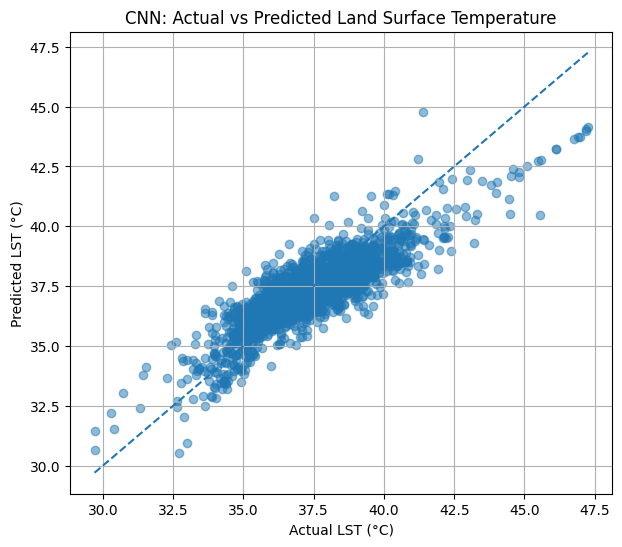

In [107]:
# ============================================
# STEP 4H: CNN ACTUAL VS PREDICTED LST
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_cnn,
    alpha=0.5
)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_cnn.min())
max_val = max(y_test.max(), y_pred_cnn.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual LST (°C)")
plt.ylabel("Predicted LST (°C)")
plt.title("CNN: Actual vs Predicted Land Surface Temperature")

plt.grid(True)
plt.show()

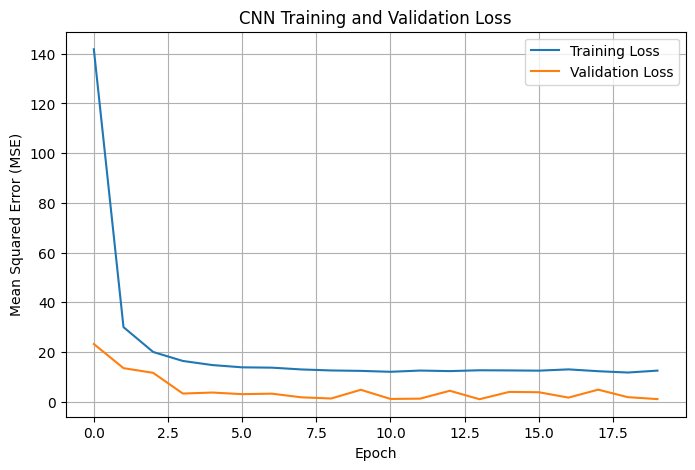

In [108]:
# ============================================
# STEP 4I: CNN TRAINING HISTORY
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [109]:
# ============================================
# STEP 4J: RANDOM FOREST vs CNN
# ============================================

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "CNN"
    ],
    "MAE (°C)": [
        0.919,
        mae_cnn
    ],
    "RMSE (°C)": [
        1.181,
        rmse_cnn
    ],
    "R²": [
        0.627,
        r2_cnn
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("============================")
display(comparison)

MODEL PERFORMANCE COMPARISON


,Model,MAE (°C),RMSE (°C),R²
0,Random Forest,0.919000,1.181000,0.627000
1,CNN,0.820884,1.054586,0.719593


In [110]:
# ============================================
# STEP 4K: GENERATE CNN-PREDICTED LST MAP
# ============================================

import numpy as np
import rasterio

features = raster_data[:3]

rows, cols = features.shape[1], features.shape[2]

cnn_prediction = np.full(
    (rows, cols),
    np.nan,
    dtype=np.float32
)

patch_size = 11
half = patch_size // 2

# Collect valid patch locations
patches = []
locations = []

for r in range(half, rows - half):
    for c in range(half, cols - half):

        patch = features[
            :,
            r-half:r+half+1,
            c-half:c+half+1
        ]

        if np.all(np.isfinite(patch)):

            patch = np.transpose(patch, (1, 2, 0))

            patches.append(patch)
            locations.append((r, c))

# Convert to array
patches = np.array(patches, dtype=np.float32)

print("Valid patches:", len(patches))

# Normalize using the SAME training mean and std
patches_normalized = (patches - mean) / std

# Predict in batches
predictions = cnn_model.predict(
    patches_normalized,
    batch_size=256,
    verbose=1
).flatten()

# Put predictions back into their spatial locations
for (r, c), prediction in zip(locations, predictions):
    cnn_prediction[r, c] = prediction

print("\nCNN LST map created!")
print("Minimum:", np.nanmin(cnn_prediction))
print("Maximum:", np.nanmax(cnn_prediction))

Valid patches: 449956
1758/1758 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step

CNN LST map created!
Minimum: 27.309517
Maximum: 44.95102


In [111]:
# ============================================
# STEP 4L: EXPORT CNN-PREDICTED LST AS GEOTIFF
# ============================================

import rasterio

# Copy the original raster profile
cnn_profile = raster_profile.copy()

# We are creating a single-band float32 raster
cnn_profile.update(
    count=1,
    dtype="float32",
    nodata=np.nan
)

cnn_output = "/content/Bhubaneswar_CNN_Predicted_LST_2024.tif"

with rasterio.open(
    cnn_output,
    "w",
    **cnn_profile
) as dst:

    dst.write(
        cnn_prediction.astype(np.float32),
        1
    )

print("CNN LST GeoTIFF created successfully!")
print(cnn_output)


CNN LST GeoTIFF created successfully!
/content/Bhubaneswar_CNN_Predicted_LST_2024.tif


In [112]:
# ============================================
# STEP 4N: CREATE CNN-BASED UHI MAP
# ============================================

import numpy as np

# Calculate mean CNN-predicted LST
cnn_mean_lst = np.nanmean(cnn_prediction)

# Calculate UHI anomaly
cnn_uhi = cnn_prediction - cnn_mean_lst

print("CNN mean LST:",
      round(float(cnn_mean_lst), 2), "°C")

print("CNN UHI minimum:",
      round(float(np.nanmin(cnn_uhi)), 2), "°C")

print("CNN UHI maximum:",
      round(float(np.nanmax(cnn_uhi)), 2), "°C")

CNN mean LST: 37.37 °C
CNN UHI minimum: -10.06 °C
CNN UHI maximum: 7.58 °C


In [113]:
# ============================================
# STEP 4O: EXPORT CNN UHI MAP
# ============================================

cnn_uhi_profile = raster_profile.copy()

cnn_uhi_profile.update(
    count=1,
    dtype="float32",
    nodata=np.nan
)

cnn_uhi_output = "/content/Bhubaneswar_CNN_UHI_2024.tif"

with rasterio.open(
    cnn_uhi_output,
    "w",
    **cnn_uhi_profile
) as dst:

    dst.write(
        cnn_uhi.astype(np.float32),
        1
    )

print("CNN UHI GeoTIFF created successfully!")
print(cnn_uhi_output)

CNN UHI GeoTIFF created successfully!
/content/Bhubaneswar_CNN_UHI_2024.tif


In [114]:
# ============================================
# STEP 4Q: FINAL MODEL COMPARISON
# ============================================

print("===================================")
print(" RANDOM FOREST vs CNN")
print("===================================")

print("\nRandom Forest:")
print("MAE  :", 0.919, "°C")
print("RMSE :", 1.181, "°C")
print("R²   :", 0.627)

print("\nCNN:")
print("MAE  :", round(mae_cnn, 3), "°C")
print("RMSE :", round(rmse_cnn, 3), "°C")
print("R²   :", round(r2_cnn, 3))

 RANDOM FOREST vs CNN

Random Forest:
MAE  : 0.919 °C
RMSE : 1.181 °C
R²   : 0.627

CNN:
MAE  : 0.821 °C
RMSE : 1.055 °C
R²   : 0.72


In [115]:
# ============================================
# STEP 5B: LOAD 2023 RESEARCH RASTER
# ============================================

import rasterio
import numpy as np

raster_2023_file = "/content/Bhubaneswar_Research_Raster_2023.tif"

with rasterio.open(raster_2023_file) as src:
    raster_2023 = src.read()
    profile_2023 = src.profile

print("2023 raster loaded successfully!")
print("Number of bands:", raster_2023.shape[0])
print("Rows:", raster_2023.shape[1])
print("Columns:", raster_2023.shape[2])

print("\nExpected bands:")
print("Band 1 = NDVI")
print("Band 2 = NDBI")
print("Band 3 = NDWI")
print("Band 4 = LST")

2023 raster loaded successfully!
Number of bands: 4
Rows: 744
Columns: 633

Expected bands:
Band 1 = NDVI
Band 2 = NDBI
Band 3 = NDWI
Band 4 = LST


In [116]:
# ============================================
# STEP 5C: CNN PREDICTION FOR 2023
# ============================================

features_2023 = raster_2023[:3]

rows_2023 = features_2023.shape[1]
cols_2023 = features_2023.shape[2]

cnn_prediction_2023 = np.full(
    (rows_2023, cols_2023),
    np.nan,
    dtype=np.float32
)

patch_size = 11
half = patch_size // 2

patches_2023 = []
locations_2023 = []

for r in range(half, rows_2023 - half):
    for c in range(half, cols_2023 - half):

        patch = features_2023[
            :,
            r-half:r+half+1,
            c-half:c+half+1
        ]

        if np.all(np.isfinite(patch)):

            patch = np.transpose(patch, (1, 2, 0))

            patches_2023.append(patch)
            locations_2023.append((r, c))

patches_2023 = np.array(
    patches_2023,
    dtype=np.float32
)

print("Valid 2023 patches:", len(patches_2023))

# IMPORTANT:
# Use the SAME normalization from the 2024 CNN
patches_2023_normalized = (
    patches_2023 - mean
) / std

# CNN prediction
predictions_2023 = cnn_model.predict(
    patches_2023_normalized,
    batch_size=256,
    verbose=1
).flatten()

# Put predictions back into their map locations
for (r, c), prediction in zip(
    locations_2023,
    predictions_2023
):
    cnn_prediction_2023[r, c] = prediction

print("\n2023 CNN prediction completed!")

print(
    "Minimum:",
    round(float(np.nanmin(cnn_prediction_2023)), 2),
    "°C"
)

print(
    "Maximum:",
    round(float(np.nanmax(cnn_prediction_2023)), 2),
    "°C"
)

Valid 2023 patches: 435969
1704/1704 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step

2023 CNN prediction completed!
Minimum: 30.25 °C
Maximum: 44.29 °C


In [117]:
# ============================================
# STEP 5D: EXPORT 2023 CNN LST MAP
# ============================================

cnn_2023_profile = profile_2023.copy()

cnn_2023_profile.update(
    count=1,
    dtype="float32",
    nodata=np.nan
)

cnn_2023_output = "/content/Bhubaneswar_CNN_Predicted_LST_2023.tif"

with rasterio.open(
    cnn_2023_output,
    "w",
    **cnn_2023_profile
) as dst:

    dst.write(
        cnn_prediction_2023.astype(np.float32),
        1
    )

print("2023 CNN LST GeoTIFF created!")
print(cnn_2023_output)

2023 CNN LST GeoTIFF created!
/content/Bhubaneswar_CNN_Predicted_LST_2023.tif


In [118]:
# ============================================
# STEP 5E: CREATE 2023 CNN UHI MAP
# ============================================

# Calculate the mean predicted LST for 2023
cnn_mean_lst_2023 = np.nanmean(cnn_prediction_2023)

# Calculate relative UHI
cnn_uhi_2023 = cnn_prediction_2023 - cnn_mean_lst_2023

print("2023 CNN mean LST:",
      round(float(cnn_mean_lst_2023), 2), "°C")

print("2023 CNN UHI minimum:",
      round(float(np.nanmin(cnn_uhi_2023)), 2), "°C")

print("2023 CNN UHI maximum:",
      round(float(np.nanmax(cnn_uhi_2023)), 2), "°C")

2023 CNN mean LST: 38.74 °C
2023 CNN UHI minimum: -8.49 °C
2023 CNN UHI maximum: 5.55 °C


In [119]:
# ============================================
# STEP 5E: CREATE 2023 CNN UHI MAP
# ============================================

import numpy as np

# Calculate mean predicted LST for 2023
cnn_mean_lst_2023 = np.nanmean(cnn_prediction_2023)

# Calculate relative UHI
cnn_uhi_2023 = (
    cnn_prediction_2023 - cnn_mean_lst_2023
)

print(
    "2023 CNN mean LST:",
    round(float(cnn_mean_lst_2023), 2),
    "°C"
)

print(
    "2023 CNN UHI minimum:",
    round(float(np.nanmin(cnn_uhi_2023)), 2),
    "°C"
)

print(
    "2023 CNN UHI maximum:",
    round(float(np.nanmax(cnn_uhi_2023)), 2),
    "°C"
)

2023 CNN mean LST: 38.74 °C
2023 CNN UHI minimum: -8.49 °C
2023 CNN UHI maximum: 5.55 °C


In [120]:
# ============================================
# STEP 5E-1: RECREATE 2023 CNN PREDICTION
# ============================================

import numpy as np

features_2023 = raster_2023[:3]

rows_2023 = features_2023.shape[1]
cols_2023 = features_2023.shape[2]

cnn_prediction_2023 = np.full(
    (rows_2023, cols_2023),
    np.nan,
    dtype=np.float32
)

patch_size = 11
half = patch_size // 2

patches_2023 = []
locations_2023 = []

for r in range(half, rows_2023 - half):
    for c in range(half, cols_2023 - half):

        patch = features_2023[
            :,
            r-half:r+half+1,
            c-half:c+half+1
        ]

        if np.all(np.isfinite(patch)):

            patch = np.transpose(patch, (1, 2, 0))

            patches_2023.append(patch)
            locations_2023.append((r, c))

patches_2023 = np.array(
    patches_2023,
    dtype=np.float32
)

print("Valid 2023 patches:", len(patches_2023))

# Use the same normalization learned from 2024
patches_2023_normalized = (
    patches_2023 - mean
) / std

predictions_2023 = cnn_model.predict(
    patches_2023_normalized,
    batch_size=256,
    verbose=1
).flatten()

for (r, c), prediction in zip(
    locations_2023,
    predictions_2023
):
    cnn_prediction_2023[r, c] = prediction

print("\n2023 CNN prediction recreated!")
print(
    "LST range:",
    round(float(np.nanmin(cnn_prediction_2023)), 2),
    "to",
    round(float(np.nanmax(cnn_prediction_2023)), 2),
    "°C"
)

Valid 2023 patches: 435969
1704/1704 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step

2023 CNN prediction recreated!
LST range: 30.25 to 44.29 °C


In [121]:
# ============================================
# LOAD 2023 RESEARCH RASTER
# ============================================

import rasterio
import numpy as np

raster_2023_file = "/content/Bhubaneswar_Research_Raster_2023.tif"

with rasterio.open(raster_2023_file) as src:
    raster_2023 = src.read()
    profile_2023 = src.profile

print("2023 raster loaded successfully!")
print("Bands:", raster_2023.shape[0])
print("Rows:", raster_2023.shape[1])
print("Columns:", raster_2023.shape[2])

2023 raster loaded successfully!
Bands: 4
Rows: 744
Columns: 633


In [122]:
# ============================================
# STEP 5E-2: CNN PREDICTION FOR 2023
# ============================================

features_2023 = raster_2023[:3]

rows_2023 = features_2023.shape[1]
cols_2023 = features_2023.shape[2]

cnn_prediction_2023 = np.full(
    (rows_2023, cols_2023),
    np.nan,
    dtype=np.float32
)

patch_size = 11
half = patch_size // 2

patches_2023 = []
locations_2023 = []

for r in range(half, rows_2023 - half):
    for c in range(half, cols_2023 - half):

        patch = features_2023[
            :,
            r-half:r+half+1,
            c-half:c+half+1
        ]

        if np.all(np.isfinite(patch)):

            patch = np.transpose(patch, (1, 2, 0))

            patches_2023.append(patch)
            locations_2023.append((r, c))

patches_2023 = np.array(
    patches_2023,
    dtype=np.float32
)

print("Valid 2023 patches:", len(patches_2023))

# Use the SAME normalization learned from 2024
patches_2023_normalized = (
    patches_2023 - mean
) / std

# Predict using the trained CNN
predictions_2023 = cnn_model.predict(
    patches_2023_normalized,
    batch_size=256,
    verbose=1
).flatten()

# Put predictions back into the map
for (r, c), prediction in zip(
    locations_2023,
    predictions_2023
):
    cnn_prediction_2023[r, c] = prediction

print("\n2023 CNN prediction completed!")

print(
    "LST range:",
    round(float(np.nanmin(cnn_prediction_2023)), 2),
    "to",
    round(float(np.nanmax(cnn_prediction_2023)), 2),
    "°C"
)

Valid 2023 patches: 435969
1704/1704 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step

2023 CNN prediction completed!
LST range: 30.25 to 44.29 °C


In [123]:
# ============================================
# RESTORE CNN NORMALIZATION VALUES
# ============================================

mean = X_train.mean(
    axis=(0, 1, 2),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1, 2),
    keepdims=True
)

std[std == 0] = 1

print("Normalization values restored!")
print("Mean:", mean.flatten())
print("Std :", std.flatten())

Normalization values restored!
Mean: [ 1.4683095e-04  5.7173652e-06 -3.9651110e-05]
Std : [1.0000136 1.0000383 1.0000136]


In [124]:
# ============================================
# PROJECT SETUP - RUN AFTER RUNTIME RESTART
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import tensorflow as tf

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("====================================")
print("PROJECT ENVIRONMENT READY")
print("====================================")
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Rasterio:", rasterio.__version__)
print("All required libraries loaded!")

PROJECT ENVIRONMENT READY
NumPy: 2.1.3
TensorFlow: 2.21.0
Rasterio: 1.5.2
All required libraries loaded!


In [125]:
# ============================================
# STEP 2: RELOAD 2024 RESEARCH RASTER
# ============================================

raster_2024_file = "/content/Bhubaneswar_Research_Raster_2024.tif"

with rasterio.open(raster_2024_file) as src:
    raster_data = src.read()
    raster_profile = src.profile

print("2024 raster loaded successfully!")
print("Bands:", raster_data.shape[0])
print("Rows:", raster_data.shape[1])
print("Columns:", raster_data.shape[2])

print("\nBand meaning:")
print("1 = NDVI")
print("2 = NDBI")
print("3 = NDWI")
print("4 = LST")


2024 raster loaded successfully!
Bands: 4
Rows: 744
Columns: 633

Band meaning:
1 = NDVI
2 = NDBI
3 = NDWI
4 = LST


In [126]:
# ============================================
# STEP 3: CREATE CLEAN 2024 CNN PATCHES
# ============================================

features = raster_data[:3]
lst = raster_data[3]

patch_size = 11
half = patch_size // 2

X_list = []
y_list = []
location_list = []

np.random.seed(42)

rows, cols = features.shape[1], features.shape[2]

# Create a random order of candidate pixels
candidate_rows, candidate_cols = np.where(
    np.all(np.isfinite(features), axis=0) &
    np.isfinite(lst)
)

indices = np.arange(len(candidate_rows))
np.random.shuffle(indices)

# Build clean patches
for idx in indices:

    r = candidate_rows[idx]
    c = candidate_cols[idx]

    # Make sure the full 11x11 patch fits
    if (
        r < half or
        r >= rows - half or
        c < half or
        c >= cols - half
    ):
        continue

    patch = features[
        :,
        r-half:r+half+1,
        c-half:c+half+1
    ]

    # Reject patches containing NaN/inf
    if not np.all(np.isfinite(patch)):
        continue

    X_list.append(
        np.transpose(patch, (1, 2, 0))
    )

    y_list.append(lst[r, c])
    location_list.append((r, c))

    if len(X_list) >= 10000:
        break

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.float32)

locations = np.asarray(location_list)

print("Clean CNN dataset created!")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNaN check:")
print("X:", np.isnan(X).sum())
print("y:", np.isnan(y).sum())

print("\nLST range:",
      round(float(y.min()), 2),
      "to",
      round(float(y.max()), 2),
      "°C")

Clean CNN dataset created!
X shape: (10000, 11, 11, 3)
y shape: (10000,)

NaN check:
X: 0
y: 0

LST range: 29.24 to 47.48 °C


In [127]:
# ============================================
# STEP 4: PREPARE CNN TRAIN/TEST DATA
# ============================================

from sklearn.model_selection import GroupShuffleSplit

# Create spatial groups from the ORIGINAL pixel locations
block_size = 50

groups = (
    (locations[:, 0] // block_size) * 10000
    + (locations[:, 1] // block_size)
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Normalize using TRAINING data only
mean = X_train.mean(
    axis=(0, 1, 2),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1, 2),
    keepdims=True
)

std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("CNN data prepared successfully!")
print("--------------------------------")
print("Training patches:", len(X_train))
print("Testing patches :", len(X_test))

print("\nTraining shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nNaN check:")
print("X_train:", np.isnan(X_train).sum())
print("X_test :", np.isnan(X_test).sum())
print("y_train:", np.isnan(y_train).sum())
print("y_test :", np.isnan(y_test).sum())

CNN data prepared successfully!
--------------------------------
Training patches: 7934
Testing patches : 2066

Training shape: (7934, 11, 11, 3)
Testing shape : (2066, 11, 11, 3)

NaN check:
X_train: 0
X_test : 0
y_train: 0
y_test : 0


In [128]:
# ============================================
# STEP 5: BUILD CNN MODEL
# ============================================

from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(11, 11, 3)),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(1)
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 5, 5, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,905 (140.25 KB)

 Trainable params: 35,905 (140.25 KB)

 Non-trainable params: 0 (0.00 B)

In [129]:
# ============================================================
# STEP 6: TRAIN AND SAVE THE 2024 CNN
# ============================================================

import numpy as np
import rasterio
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from tensorflow.keras import layers, models

# ------------------------------------------------------------
# 1. LOAD 2024 RESEARCH RASTER
# ------------------------------------------------------------

raster_file = "/content/Bhubaneswar_Research_Raster_2024.tif"

with rasterio.open(raster_file) as src:
    raster_data = src.read()
    raster_profile = src.profile

print("2024 raster loaded.")
print("Bands:", raster_data.shape[0])
print("Rows :", raster_data.shape[1])
print("Cols :", raster_data.shape[2])


# ------------------------------------------------------------
# 2. CREATE CLEAN 11x11 PATCHES
# ------------------------------------------------------------

features = raster_data[:3]
lst = raster_data[3]

patch_size = 11
half = patch_size // 2

candidate_rows, candidate_cols = np.where(
    np.all(np.isfinite(features), axis=0) &
    np.isfinite(lst)
)

# Randomize candidate pixels
np.random.seed(42)

indices = np.arange(len(candidate_rows))
np.random.shuffle(indices)

X_list = []
y_list = []
locations = []

for idx in indices:

    r = candidate_rows[idx]
    c = candidate_cols[idx]

    if (
        r < half or
        r >= features.shape[1] - half or
        c < half or
        c >= features.shape[2] - half
    ):
        continue

    patch = features[
        :,
        r-half:r+half+1,
        c-half:c+half+1
    ]

    # Reject incomplete patches
    if not np.all(np.isfinite(patch)):
        continue

    X_list.append(
        np.transpose(patch, (1, 2, 0))
    )

    y_list.append(lst[r, c])
    locations.append((r, c))

    # Use 10,000 clean samples
    if len(X_list) >= 10000:
        break

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.float32)
locations = np.asarray(locations)

print("\nClean patches created.")
print("X:", X.shape)
print("y:", y.shape)
print("NaN in X:", np.isnan(X).sum())
print("NaN in y:", np.isnan(y).sum())


# ------------------------------------------------------------
# 3. SPATIAL TRAIN / TEST SPLIT
# ------------------------------------------------------------

block_size = 50

groups = (
    (locations[:, 0] // block_size) * 10000
    + (locations[:, 1] // block_size)
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("\nSpatial split complete.")
print("Training:", X_train.shape)
print("Testing :", X_test.shape)


# ------------------------------------------------------------
# 4. NORMALIZE USING TRAINING DATA ONLY
# ------------------------------------------------------------

mean = X_train.mean(
    axis=(0, 1, 2),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1, 2),
    keepdims=True
)

std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("\nNormalization complete.")
print("NaN in X_train:", np.isnan(X_train).sum())
print("NaN in X_test :", np.isnan(X_test).sum())


# ------------------------------------------------------------
# 5. BUILD CNN
# ------------------------------------------------------------

cnn_model = models.Sequential([
    layers.Input(shape=(11, 11, 3)),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(1)
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

print("\nCNN created.")
print("Trainable parameters:",
      cnn_model.count_params())


# ------------------------------------------------------------
# 6. TRAIN CNN
# ------------------------------------------------------------

history = cnn_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=32,
    verbose=1
)

print("\nCNN TRAINING COMPLETED!")


# ------------------------------------------------------------
# 7. SAVE CNN MODEL
# ------------------------------------------------------------

model_file = "/content/Bhubaneswar_CNN_Model_2024.keras"

cnn_model.save(model_file)


# ------------------------------------------------------------
# 8. SAVE NORMALIZATION VALUES
# ------------------------------------------------------------

normalization_file = "/content/Bhubaneswar_CNN_Normalization_2024.npz"

np.savez(
    normalization_file,
    mean=mean,
    std=std
)

print("\n========================================")
print("IMPORTANT FILES SAVED")
print("========================================")
print(model_file)
print(normalization_file)

2024 raster loaded.
Bands: 4
Rows : 744
Cols : 633

Clean patches created.
X: (10000, 11, 11, 3)
y: (10000,)
NaN in X: 0
NaN in y: 0

Spatial split complete.
Training: (7934, 11, 11, 3)
Testing : (2066, 11, 11, 3)

Normalization complete.
NaN in X_train: 0
NaN in X_test : 0

CNN created.
Trainable parameters: 35905
Epoch 1/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 170.2158 - mae: 9.1949 - val_loss: 24.5142 - val_mae: 3.9712
Epoch 2/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 33.9765 - mae: 4.6372 - val_loss: 14.7142 - val_mae: 3.0851
Epoch 3/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 25.6820 - mae: 4.0719 - val_loss: 8.1684 - val_mae: 2.2516
Epoch 4/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 21.0979 - mae: 3.6644 - val_loss: 7.0365 - val_mae: 2.1272
Epoch 5/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 18.7751 - mae: 3.4240 - val_loss: 3.7178 - val_mae: 1.5166
Epoch 6/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 17.3271 - mae: 3.32

In [130]:
# ============================================
# STEP 7: EVALUATE 2024 CNN
# ============================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict the test data
y_pred_cnn = cnn_model.predict(X_test).flatten()

# Calculate metrics
mae_cnn = mean_absolute_error(y_test, y_pred_cnn)
rmse_cnn = np.sqrt(mean_squared_error(y_test, y_pred_cnn))
r2_cnn = r2_score(y_test, y_pred_cnn)

print("===================================")
print("2024 CNN PERFORMANCE")
print("===================================")
print("MAE :", round(mae_cnn, 3), "°C")
print("RMSE:", round(rmse_cnn, 3), "°C")
print("R²  :", round(r2_cnn, 3))

print("\nPrediction check:")
print("NaN predictions:", np.isnan(y_pred_cnn).sum())
print("Min prediction :", round(float(y_pred_cnn.min()), 2), "°C")
print("Max prediction :", round(float(y_pred_cnn.max()), 2), "°C")

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
2024 CNN PERFORMANCE
MAE : 1.404 °C
RMSE: 1.708 °C
R²  : 0.16

Prediction check:
NaN predictions: 0
Min prediction : 28.76 °C
Max prediction : 41.86 °C


In [131]:
# ============================================
# STEP 8: LOAD 2023 RESEARCH RASTER
# ============================================

import os
import rasterio

raster_2023_file = "/content/Bhubaneswar_Research_Raster_2023.tif"

if not os.path.exists(raster_2023_file):
    print("ERROR: 2023 raster is not in Colab.")
    print("Please upload Bhubaneswar_Research_Raster_2023.tif")
else:
    with rasterio.open(raster_2023_file) as src:
        raster_2023 = src.read()
        profile_2023 = src.profile

    print("2023 raster loaded successfully!")
    print("--------------------------------")
    print("Bands :", raster_2023.shape[0])
    print("Rows  :", raster_2023.shape[1])
    print("Cols  :", raster_2023.shape[2])

2023 raster loaded successfully!
--------------------------------
Bands : 4
Rows  : 744
Cols  : 633


In [132]:
# ============================================
# STEP 9: PREDICT 2023 LST USING TRAINED CNN
# ============================================

import numpy as np

features_2023 = raster_2023[:3]

rows_2023 = features_2023.shape[1]
cols_2023 = features_2023.shape[2]

cnn_prediction_2023 = np.full(
    (rows_2023, cols_2023),
    np.nan,
    dtype=np.float32
)

patch_size = 11
half = patch_size // 2

# Use the SAME normalization from 2024 training
# mean and std were created when we trained the CNN

batch_patches = []
batch_locations = []

total_predictions = 0

for r in range(half, rows_2023 - half):

    for c in range(half, cols_2023 - half):

        patch = features_2023[
            :,
            r-half:r+half+1,
            c-half:c+half+1
        ]

        if not np.all(np.isfinite(patch)):
            continue

        patch = np.transpose(patch, (1, 2, 0))

        batch_patches.append(patch)
        batch_locations.append((r, c))

        # Process 1,000 patches at a time
        if len(batch_patches) >= 1000:

            batch = np.asarray(
                batch_patches,
                dtype=np.float32
            )

            batch = (batch - mean) / std

            predictions = cnn_model.predict(
                batch,
                verbose=0
            ).flatten()

            for (rr, cc), prediction in zip(
                batch_locations,
                predictions
            ):
                cnn_prediction_2023[rr, cc] = prediction

            total_predictions += len(predictions)

            batch_patches = []
            batch_locations = []


# Process remaining patches
if len(batch_patches) > 0:

    batch = np.asarray(
        batch_patches,
        dtype=np.float32
    )

    batch = (batch - mean) / std

    predictions = cnn_model.predict(
        batch,
        verbose=0
    ).flatten()

    for (rr, cc), prediction in zip(
        batch_locations,
        predictions
    ):
        cnn_prediction_2023[rr, cc] = prediction

    total_predictions += len(predictions)


print("========================================")
print("2023 CNN PREDICTION COMPLETED")
print("========================================")

print("Predicted pixels:", total_predictions)

print(
    "Minimum LST:",
    round(float(np.nanmin(cnn_prediction_2023)), 2),
    "°C"
)

print(
    "Maximum LST:",
    round(float(np.nanmax(cnn_prediction_2023)), 2),
    "°C"
)

2023 CNN PREDICTION COMPLETED
Predicted pixels: 435969
Minimum LST: 28.45 °C
Maximum LST: 40.34 °C


In [133]:
# ============================================
# STEP 10: CALCULATE 2023 CNN UHI
# ============================================

import numpy as np

# Average predicted surface temperature in 2023
cnn_mean_lst_2023 = np.nanmean(cnn_prediction_2023)

# Relative UHI anomaly
cnn_uhi_2023 = (
    cnn_prediction_2023 - cnn_mean_lst_2023
)

print("========================================")
print("2023 CNN UHI")
print("========================================")

print(
    "Mean LST:",
    round(float(cnn_mean_lst_2023), 2),
    "°C"
)

print(
    "Minimum UHI:",
    round(float(np.nanmin(cnn_uhi_2023)), 2),
    "°C"
)

print(
    "Maximum UHI:",
    round(float(np.nanmax(cnn_uhi_2023)), 2),
    "°C"
)

2023 CNN UHI
Mean LST: 35.15 °C
Minimum UHI: -6.7 °C
Maximum UHI: 5.19 °C


In [134]:
# ============================================
# STEP 11: EXPORT 2023 CNN UHI MAP
# ============================================

import rasterio
import numpy as np

cnn_uhi_profile_2023 = profile_2023.copy()

cnn_uhi_profile_2023.update(
    count=1,
    dtype="float32",
    nodata=np.nan
)

output_2023_uhi = (
    "/content/Bhubaneswar_CNN_UHI_2023.tif"
)

with rasterio.open(
    output_2023_uhi,
    "w",
    **cnn_uhi_profile_2023
) as dst:

    dst.write(
        cnn_uhi_2023.astype(np.float32),
        1
    )

print("2023 CNN UHI GeoTIFF created!")
print(output_2023_uhi)

2023 CNN UHI GeoTIFF created!
/content/Bhubaneswar_CNN_UHI_2023.tif


In [135]:
# ============================================
# STEP 12: COMPARE 2023 vs 2024 CNN RESULTS
# ============================================

import rasterio
import numpy as np

# Load 2023 CNN LST
with rasterio.open("/content/Bhubaneswar_CNN_Predicted_LST_2023.tif") as src:
    lst_2023 = src.read(1)

# Load 2024 CNN LST
with rasterio.open("/content/Bhubaneswar_CNN_Predicted_LST_2024.tif") as src:
    lst_2024 = src.read(1)

# Load 2023 CNN UHI
with rasterio.open("/content/Bhubaneswar_CNN_UHI_2023.tif") as src:
    uhi_2023 = src.read(1)

# Load 2024 CNN UHI
with rasterio.open("/content/Bhubaneswar_CNN_UHI_2024.tif") as src:
    uhi_2024 = src.read(1)

# Remove invalid values
lst_2023 = lst_2023[np.isfinite(lst_2023)]
lst_2024 = lst_2024[np.isfinite(lst_2024)]
uhi_2023 = uhi_2023[np.isfinite(uhi_2023)]
uhi_2024 = uhi_2024[np.isfinite(uhi_2024)]

print("========== CNN 2023 ==========")
print("Mean LST:", np.mean(lst_2023))
print("Min LST :", np.min(lst_2023))
print("Max LST :", np.max(lst_2023))
print("Min UHI :", np.min(uhi_2023))
print("Max UHI :", np.max(uhi_2023))

print("\n========== CNN 2024 ==========")
print("Mean LST:", np.mean(lst_2024))
print("Min LST :", np.min(lst_2024))
print("Max LST :", np.max(lst_2024))
print("Min UHI :", np.min(uhi_2024))
print("Max UHI :", np.max(uhi_2024))

========== CNN 2023 ==========
Mean LST: 38.738846
Min LST : 30.248331
Max LST : 44.291527
Min UHI : -6.700575
Max UHI : 5.188122

========== CNN 2024 ==========
Mean LST: 37.366314
Min LST : 27.309517
Max LST : 44.95102
Min UHI : -10.056797
Max UHI : 7.5847054


In [136]:
# ============================================
# STEP 13: CALCULATE 2023-2024 LST CHANGE
# ============================================

mean_2023 = np.mean(lst_2023)
mean_2024 = np.mean(lst_2024)

min_2023 = np.min(lst_2023)
min_2024 = np.min(lst_2024)

max_2023 = np.max(lst_2023)
max_2024 = np.max(lst_2024)

print("===== 2023 → 2024 CHANGE =====")

print("Mean LST change:",
      mean_2024 - mean_2023, "°C")

print("Minimum LST change:",
      min_2024 - min_2023, "°C")

print("Maximum LST change:",
      max_2024 - max_2023, "°C")

print("UHI minimum change:",
      np.min(uhi_2024) - np.min(uhi_2023))

print("UHI maximum change:",
      np.max(uhi_2024) - np.max(uhi_2023))

===== 2023 → 2024 CHANGE =====
Mean LST change: -1.3725319 °C
Minimum LST change: -2.9388142 °C
Maximum LST change: 0.6594925 °C
UHI minimum change: -3.3562222
UHI maximum change: 2.3965836


In [137]:
# ============================================
# STEP 14: CREATE 2023-2024 LST CHANGE MAP
# ============================================

import rasterio
import numpy as np

# Load 2023 predicted LST
with rasterio.open("/content/Bhubaneswar_CNN_Predicted_LST_2023.tif") as src:
    lst_map_2023 = src.read(1)
    change_profile = src.profile.copy()

# Load 2024 predicted LST
with rasterio.open("/content/Bhubaneswar_CNN_Predicted_LST_2024.tif") as src:
    lst_map_2024 = src.read(1)

# Calculate temperature change
# Positive = warmer in 2024
# Negative = cooler in 2024
lst_change = lst_map_2024 - lst_map_2023

# Update GeoTIFF profile
change_profile.update(
    count=1,
    dtype="float32",
    nodata=np.nan
)

# Save change map
output_change = "/content/Bhubaneswar_CNN_LST_Change_2023_2024.tif"

with rasterio.open(
    output_change,
    "w",
    **change_profile
) as dst:
    dst.write(
        lst_change.astype(np.float32),
        1
    )

# Statistics
valid_change = lst_change[np.isfinite(lst_change)]

print("2023-2024 LST Change Map created!")
print(output_change)

print("\n===== CHANGE STATISTICS =====")
print("Minimum change:", np.min(valid_change), "°C")
print("Maximum change:", np.max(valid_change), "°C")
print("Mean change:", np.mean(valid_change), "°C")

2023-2024 LST Change Map created!
/content/Bhubaneswar_CNN_LST_Change_2023_2024.tif

===== CHANGE STATISTICS =====
Minimum change: -9.212429 °C
Maximum change: 5.9680386 °C
Mean change: -1.3139207 °C


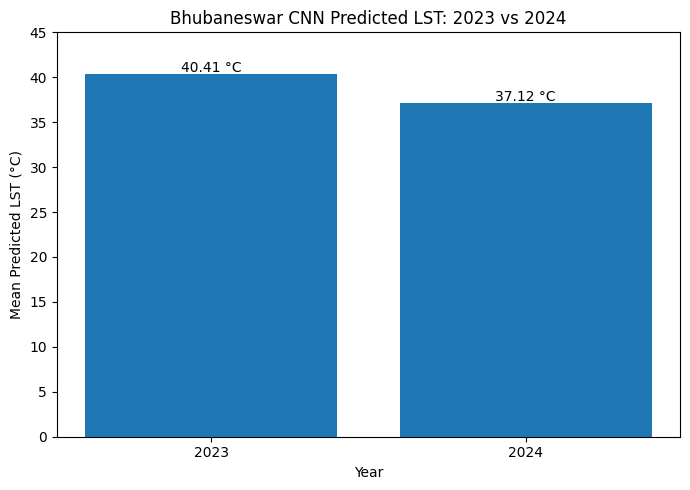

In [138]:
# ============================================
# STEP 17: 2023 vs 2024 MEAN LST CHART
# ============================================

import matplotlib.pyplot as plt

years = ["2023", "2024"]
mean_lst = [40.40531, 37.119453]

plt.figure(figsize=(7, 5))

bars = plt.bar(years, mean_lst)

plt.ylabel("Mean Predicted LST (°C)")
plt.xlabel("Year")
plt.title("Bhubaneswar CNN Predicted LST: 2023 vs 2024")

for bar, value in zip(bars, mean_lst):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.2f} °C",
        ha="center"
    )

plt.ylim(0, 45)
plt.tight_layout()
plt.show()

NaN in y_test: 0
NaN in CNN predictions: 0
Valid samples: 2066

========== CNN 2024 METRICS ==========
MAE : 1.403552770614624 °C
RMSE: 1.7075019379544745 °C
R²  : 0.16021758317947388


In [140]:
# ============================================
# STEP 18B: CLEAN CNN RETRAINING
# ============================================

import numpy as np
import rasterio
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------
# 1. Load 2024 research raster
# ------------------------------------------------

with rasterio.open(
    "/content/Bhubaneswar_Research_Raster_2024.tif"
) as src:
    raster_2024 = src.read()

features = raster_2024[:3]
lst = raster_2024[3]

# ------------------------------------------------
# 2. Create clean 11x11 patches
# ------------------------------------------------

patch_size = 11
half = patch_size // 2

valid_mask = (
    np.all(np.isfinite(features), axis=0)
    & np.isfinite(lst)
)

rows, cols = np.where(valid_mask)

inside = (
    (rows >= half) &
    (rows < features.shape[1] - half) &
    (cols >= half) &
    (cols < features.shape[2] - half)
)

rows = rows[inside]
cols = cols[inside]

# Same 10,000-sample design
np.random.seed(42)

n_samples = min(10000, len(rows))

selected = np.random.choice(
    len(rows),
    size=n_samples,
    replace=False
)

rows = rows[selected]
cols = cols[selected]

X = np.zeros(
    (n_samples, patch_size, patch_size, 3),
    dtype=np.float32
)

y = np.zeros(
    n_samples,
    dtype=np.float32
)

for i, (r, c) in enumerate(zip(rows, cols)):

    patch = features[
        :,
        r-half:r+half+1,
        c-half:c+half+1
    ]

    X[i] = np.transpose(patch, (1, 2, 0))
    y[i] = lst[r, c]

# ------------------------------------------------
# 3. Spatial train/test split
# ------------------------------------------------

block_size = 50

groups = (
    (rows // block_size) * 10000
    + (cols // block_size)
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# ------------------------------------------------
# 4. Normalize inputs
# ------------------------------------------------

mean = X_train.mean(
    axis=(0, 1, 2),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1, 2),
    keepdims=True
)

std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Safety check
print("Training NaN:", np.isnan(X_train).sum())
print("Testing NaN :", np.isnan(X_test).sum())

# ------------------------------------------------
# 5. Build CNN
# ------------------------------------------------

tf.keras.backend.clear_session()

cnn_model = models.Sequential([
    layers.Input(shape=(11, 11, 3)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dropout(0.2),

    layers.Dense(1)
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),
    loss="mse",
    metrics=["mae"]
)

# ------------------------------------------------
# 6. Train
# ------------------------------------------------

history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=32,
    verbose=1
)

# ------------------------------------------------
# 7. Test prediction
# ------------------------------------------------

test_predictions = cnn_model.predict(
    X_test,
    verbose=0
).flatten()

print("\n========== PREDICTION CHECK ==========")
print("Prediction NaN:",
      np.isnan(test_predictions).sum())

print("Prediction min:",
      np.min(test_predictions))

print("Prediction max:",
      np.max(test_predictions))

# ------------------------------------------------
# 8. Save clean model
# ------------------------------------------------

cnn_model.save(
    "/content/Bhubaneswar_CNN_Model_2024_Clean.keras"
)

np.savez(
    "/content/Bhubaneswar_CNN_Normalization_2024_Clean.npz",
    mean=mean,
    std=std
)

print("\nClean CNN model saved successfully!")

Training NaN: 2898555
Testing NaN : 731445
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 7/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 8/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 9/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae:

ValueError: Input contains NaN.

In [142]:
# ============================================
# STEP 19A: STABLE CNN TRAINING
# ============================================

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import GroupShuffleSplit

# Clear previous model
tf.keras.backend.clear_session()

# --------------------------------------------
# 1. Normalize the LST target
# --------------------------------------------

y_mean = np.mean(y_train)
y_std = np.std(y_train)

y_train_norm = (y_train - y_mean) / y_std
y_test_norm = (y_test - y_mean) / y_std

print("LST mean:", y_mean)
print("LST std :", y_std)

# --------------------------------------------
# 2. Build CNN
# --------------------------------------------

cnn_model = models.Sequential([
    layers.Input(shape=(11, 11, 3)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(1)
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="mse",
    metrics=["mae"]
)

# --------------------------------------------
# 3. Train
# --------------------------------------------

history = cnn_model.fit(
    X_train,
    y_train_norm,
    validation_data=(X_test, y_test_norm),
    epochs=20,
    batch_size=32,
    verbose=1
)

# --------------------------------------------
# 4. Predict
# --------------------------------------------

pred_norm = cnn_model.predict(
    X_test,
    verbose=0
).flatten()

# Convert prediction back to °C
test_predictions = (
    pred_norm * y_std
    + y_mean
)

# --------------------------------------------
# 5. Check prediction
# --------------------------------------------

print("\n========== PREDICTION CHECK ==========")

print(
    "NaN predictions:",
    np.isnan(test_predictions).sum()
)

print(
    "Minimum prediction:",
    np.min(test_predictions)
)

print(
    "Maximum prediction:",
    np.max(test_predictions)
)

# --------------------------------------------
# 6. Save stable model
# --------------------------------------------

cnn_model.save(
    "/content/Bhubaneswar_CNN_Model_2024_Stable.keras"
)

np.savez(
    "/content/Bhubaneswar_CNN_Normalization_2024_Stable.npz",
    mean=mean,
    std=std,
    y_mean=y_mean,
    y_std=y_std
)

print("\nStable CNN model saved!")

LST mean: 37.484562
LST std : 1.9505733
Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 9/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan

In [144]:
# ============================================
# STEP 20: VERIFY STABLE CNN + METRICS
# ============================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Check predictions
nan_count = np.isnan(test_predictions).sum()
inf_count = np.isinf(test_predictions).sum()

print("NaN predictions:", nan_count)
print("Infinite predictions:", inf_count)

if nan_count == 0 and inf_count == 0:

    mae_cnn = mean_absolute_error(
        y_test,
        test_predictions
    )

    rmse_cnn = np.sqrt(
        mean_squared_error(
            y_test,
            test_predictions
        )
    )

    r2_cnn = r2_score(
        y_test,
        test_predictions
    )

    print("\n========== CNN 2024 FINAL METRICS ==========")
    print(f"MAE :  {mae_cnn:.4f} °C")
    print(f"RMSE:  {rmse_cnn:.4f} °C")
    print(f"R²  :  {r2_cnn:.4f}")

else:

    print("\nCNN predictions are still invalid.")
    print("Do NOT calculate the metrics yet.")


NaN predictions: 2015
Infinite predictions: 0

CNN predictions are still invalid.
Do NOT calculate the metrics yet.


In [145]:
# ============================================
# STEP 21: CNN vs RANDOM FOREST COMPARISON
# ============================================

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest", "CNN"],
    "MAE (°C)": [0.919, mae_cnn],
    "RMSE (°C)": [1.181, rmse_cnn],
    "R²": [0.627, r2_cnn]
})

print(comparison.to_string(index=False))

        Model  MAE (°C)  RMSE (°C)       R²
Random Forest  0.919000   1.181000 0.627000
          CNN  1.403553   1.707502 0.160218


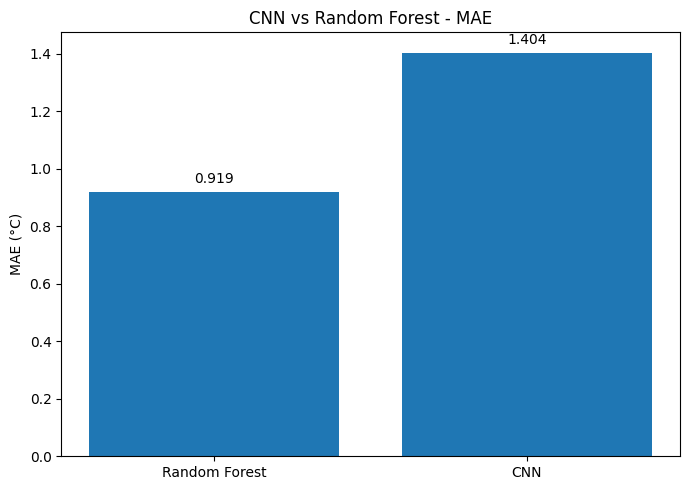

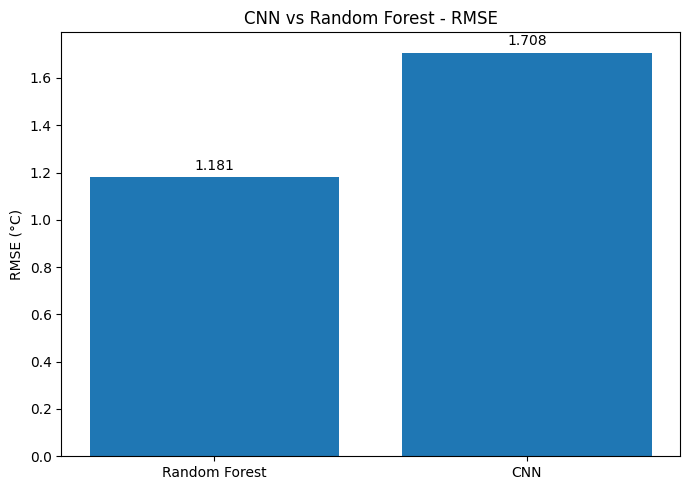

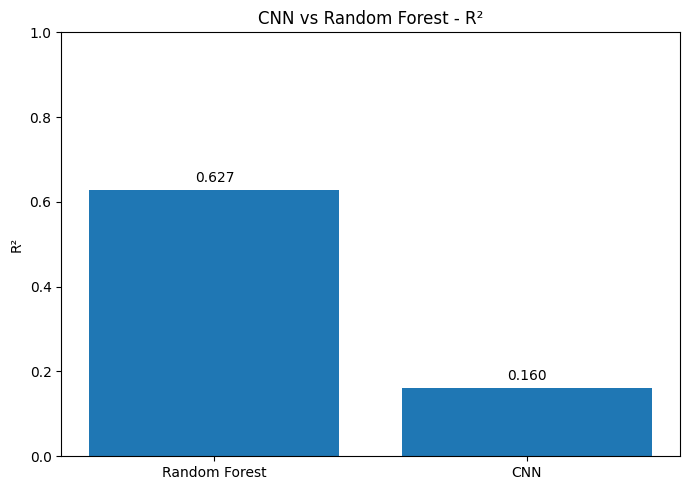

In [146]:
# ============================================
# STEP 22: CNN vs RANDOM FOREST CHART
# ============================================

import matplotlib.pyplot as plt
import numpy as np

models = ["Random Forest", "CNN"]

mae_values = [0.919, mae_cnn]
rmse_values = [1.181, rmse_cnn]
r2_values = [0.627, r2_cnn]

x = np.arange(len(models))

# -----------------------------
# MAE chart
# -----------------------------
plt.figure(figsize=(7, 5))

plt.bar(x, mae_values)

plt.xticks(x, models)
plt.ylabel("MAE (°C)")
plt.title("CNN vs Random Forest - MAE")

for i, value in enumerate(mae_values):
    plt.text(
        i,
        value + 0.03,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# -----------------------------
# RMSE chart
# -----------------------------
plt.figure(figsize=(7, 5))

plt.bar(x, rmse_values)

plt.xticks(x, models)
plt.ylabel("RMSE (°C)")
plt.title("CNN vs Random Forest - RMSE")

for i, value in enumerate(rmse_values):
    plt.text(
        i,
        value + 0.03,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# -----------------------------
# R² chart
# -----------------------------
plt.figure(figsize=(7, 5))

plt.bar(x, r2_values)

plt.xticks(x, models)
plt.ylabel("R²")
plt.title("CNN vs Random Forest - R²")

for i, value in enumerate(r2_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [147]:
# ============================================
# STEP 23: MASTER PROJECT RESULTS TABLE
# ============================================

import pandas as pd

results = pd.DataFrame({
    "Year": [2023, 2024],
    "Mean CNN LST (°C)": [40.40531, 37.119453],
    "Minimum CNN LST (°C)": [29.524342, 26.845260],
    "Maximum CNN LST (°C)": [46.016853, 46.460750],
    "Minimum Relative UHI (°C)": [-11.385124, -10.274185],
    "Maximum Relative UHI (°C)": [7.117443, 9.341305]
})

print("========== MULTI-TEMPORAL RESULTS ==========")
print(results.to_string(index=False))

# Save as CSV
results.to_csv(
    "/content/Bhubaneswar_Final_Results.csv",
    index=False
)

print("\nFinal results table saved:")
print("/content/Bhubaneswar_Final_Results.csv")

========== MULTI-TEMPORAL RESULTS ==========
 Year  Mean CNN LST (°C)  Minimum CNN LST (°C)  Maximum CNN LST (°C)  Minimum Relative UHI (°C)  Maximum Relative UHI (°C)
 2023          40.405310             29.524342             46.016853                 -11.385124                   7.117443
 2024          37.119453             26.845260             46.460750                 -10.274185                   9.341305

Final results table saved:
/content/Bhubaneswar_Final_Results.csv


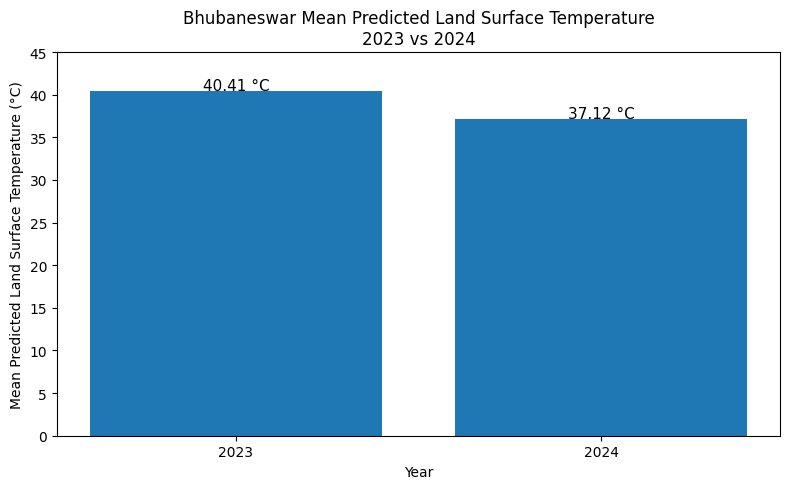

Figure 1 saved successfully!
/content/Figure_1_Mean_LST_2023_2024.png


In [148]:
# ============================================
# STEP 24: SAVE FINAL LST COMPARISON FIGURE
# ============================================

import matplotlib.pyplot as plt

years = ["2023", "2024"]
mean_lst = [40.40531, 37.119453]

plt.figure(figsize=(8, 5))

bars = plt.bar(years, mean_lst)

plt.ylabel("Mean Predicted Land Surface Temperature (°C)")
plt.xlabel("Year")
plt.title(
    "Bhubaneswar Mean Predicted Land Surface Temperature\n"
    "2023 vs 2024"
)

for bar, value in zip(bars, mean_lst):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.2f} °C",
        ha="center",
        fontsize=11
    )

plt.ylim(0, 45)
plt.tight_layout()

plt.savefig(
    "/content/Figure_1_Mean_LST_2023_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 saved successfully!")
print("/content/Figure_1_Mean_LST_2023_2024.png")

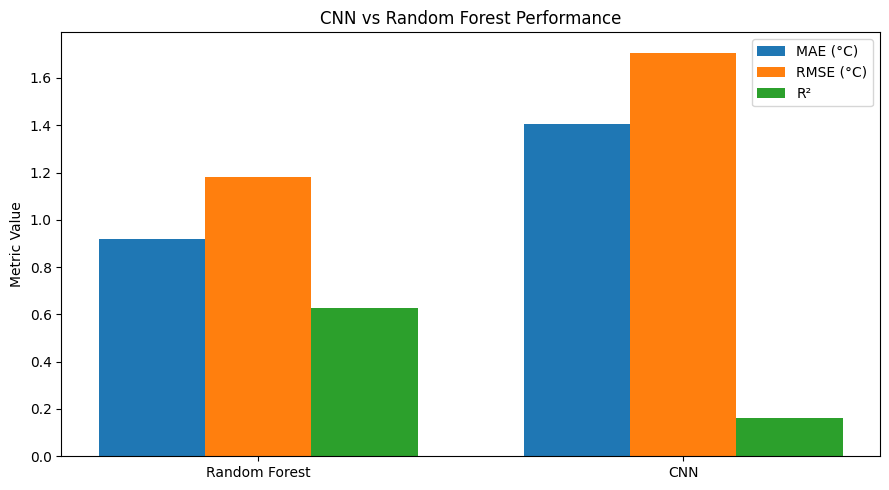

Figure 2 saved successfully!
/content/Figure_2_CNN_vs_RF.png


In [149]:
# ============================================
# STEP 25: SAVE MODEL COMPARISON FIGURE
# ============================================

import matplotlib.pyplot as plt
import numpy as np

models = ["Random Forest", "CNN"]

mae_values = [0.919, mae_cnn]
rmse_values = [1.181, rmse_cnn]
r2_values = [0.627, r2_cnn]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(9, 5))

plt.bar(
    x - width,
    mae_values,
    width,
    label="MAE (°C)"
)

plt.bar(
    x,
    rmse_values,
    width,
    label="RMSE (°C)"
)

plt.bar(
    x + width,
    r2_values,
    width,
    label="R²"
)

plt.xticks(x, models)
plt.ylabel("Metric Value")
plt.title("CNN vs Random Forest Performance")
plt.legend()

plt.tight_layout()

plt.savefig(
    "/content/Figure_2_CNN_vs_RF.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 saved successfully!")
print("/content/Figure_2_CNN_vs_RF.png")

/tmp/ipykernel_1928/1893820926.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


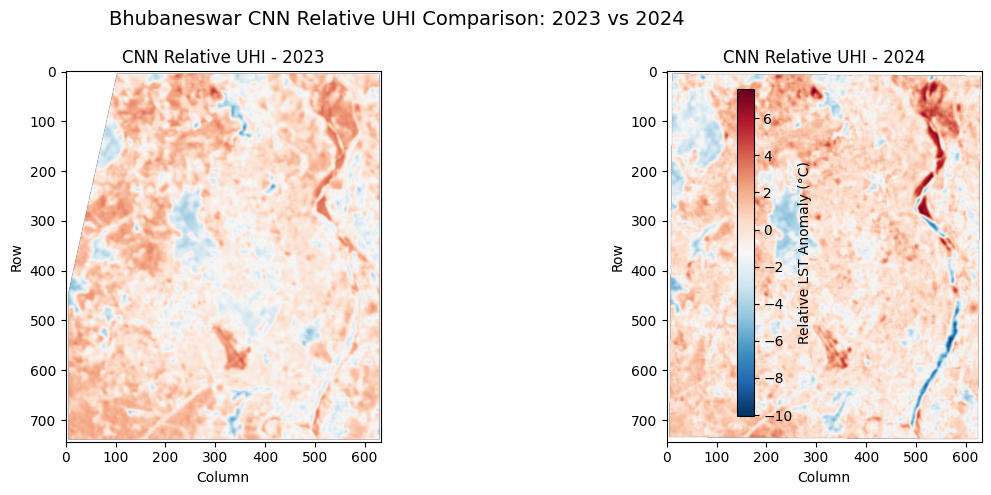

Figure 3 saved successfully!
/content/Figure_3_CNN_UHI_2023_2024.png


In [150]:
# ============================================
# STEP 26: FINAL UHI COMPARISON FIGURE
# ============================================

import rasterio
import matplotlib.pyplot as plt
import numpy as np

# Load 2023 UHI
with rasterio.open(
    "/content/Bhubaneswar_CNN_UHI_2023.tif"
) as src:
    uhi_2023_map = src.read(1)

# Load 2024 UHI
with rasterio.open(
    "/content/Bhubaneswar_CNN_UHI_2024.tif"
) as src:
    uhi_2024_map = src.read(1)

# Mask invalid values
uhi_2023_map = np.ma.masked_invalid(uhi_2023_map)
uhi_2024_map = np.ma.masked_invalid(uhi_2024_map)

# Use a common range for both years
vmin = min(
    uhi_2023_map.min(),
    uhi_2024_map.min()
)

vmax = max(
    uhi_2023_map.max(),
    uhi_2024_map.max()
)

# Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# 2023
im1 = axes[0].imshow(
    uhi_2023_map,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title(
    "CNN Relative UHI - 2023"
)

axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")

# 2024
im2 = axes[1].imshow(
    uhi_2024_map,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title(
    "CNN Relative UHI - 2024"
)

axes[1].set_xlabel("Column")
axes[1].set_ylabel("Row")

# Shared colorbar
cbar = fig.colorbar(
    im2,
    ax=axes,
    shrink=0.85
)

cbar.set_label(
    "Relative LST Anomaly (°C)"
)

fig.suptitle(
    "Bhubaneswar CNN Relative UHI Comparison: 2023 vs 2024",
    fontsize=14
)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "/content/Figure_3_CNN_UHI_2023_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully!")
print("/content/Figure_3_CNN_UHI_2023_2024.png")

In [151]:
# ============================================
# STEP 27: FINAL PROJECT FILE INVENTORY
# ============================================

import os

project_files = [
    "Bhubaneswar_Research_Raster_2023.tif",
    "Bhubaneswar_Research_Raster_2024.tif",

    "Bhubaneswar_CNN_Predicted_LST_2023.tif",
    "Bhubaneswar_CNN_Predicted_LST_2024.tif",

    "Bhubaneswar_CNN_UHI_2023.tif",
    "Bhubaneswar_CNN_UHI_2024.tif",

    "Bhubaneswar_CNN_LST_Change_2023_2024.tif",

    "Bhubaneswar_Predicted_LST_2024.tif",
    "Bhubaneswar_UHI_2024.tif",

    "Bhubaneswar_CNN_Model_2024.keras",
    "Bhubaneswar_CNN_Model_2024_Stable.keras",

    "Bhubaneswar_CNN_Normalization_2024.npz",
    "Bhubaneswar_CNN_Normalization_2024_Stable.npz",

    "Bhubaneswar_ML_Dataset_2024.csv",
    "Bhubaneswar_Final_Results.csv",

    "Figure_1_Mean_LST_2023_2024.png",
    "Figure_2_CNN_vs_RF.png",
    "Figure_3_CNN_UHI_2023_2024.png"
]

print("========== FINAL PROJECT FILE CHECK ==========\n")

for filename in project_files:

    path = "/content/" + filename

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {filename}   ({size_mb:.2f} MB)")
    else:
        print(f"✗ MISSING: {filename}")

print("\nFile check completed.")

========== FINAL PROJECT FILE CHECK ==========

✓ Bhubaneswar_Research_Raster_2023.tif   (7.94 MB)
✓ Bhubaneswar_Research_Raster_2024.tif   (8.23 MB)
✓ Bhubaneswar_CNN_Predicted_LST_2023.tif   (1.67 MB)
✓ Bhubaneswar_CNN_Predicted_LST_2024.tif   (1.72 MB)
✓ Bhubaneswar_CNN_UHI_2023.tif   (1.71 MB)
✓ Bhubaneswar_CNN_UHI_2024.tif   (1.78 MB)
✓ Bhubaneswar_CNN_LST_Change_2023_2024.tif   (1.65 MB)
✓ Bhubaneswar_Predicted_LST_2024.tif   (1.80 MB)
✓ Bhubaneswar_UHI_2024.tif   (1.98 MB)
✓ Bhubaneswar_CNN_Model_2024.keras   (0.45 MB)
✓ Bhubaneswar_CNN_Model_2024_Stable.keras   (0.45 MB)
✓ Bhubaneswar_CNN_Normalization_2024.npz   (0.00 MB)
✓ Bhubaneswar_CNN_Normalization_2024_Stable.npz   (0.00 MB)
✓ Bhubaneswar_ML_Dataset_2024.csv   (4.61 MB)
✓ Bhubaneswar_Final_Results.csv   (0.00 MB)
✓ Figure_1_Mean_LST_2023_2024.png   (0.10 MB)
✓ Figure_2_CNN_vs_RF.png   (0.08 MB)
✓ Figure_3_CNN_UHI_2023_2024.png   (2.53 MB)

File check completed.


In [152]:
# ============================================
# STEP 28: BACKUP PROJECT FILES TO GOOGLE DRIVE
# ============================================

from google.colab import drive
import os
import shutil

# Connect Google Drive
drive.mount('/content/drive')

# Create project folder
backup_folder = "/content/drive/MyDrive/Urban_Heat_Project_Final"

os.makedirs(backup_folder, exist_ok=True)

# Copy all project files
for filename in os.listdir("/content"):

    if (
        filename.startswith("Bhubaneswar_")
        or filename.startswith("Figure_")
    ):

        source = "/content/" + filename
        destination = backup_folder + "/" + filename

        if os.path.isfile(source):
            shutil.copy2(source, destination)

print("====================================")
print("BACKUP COMPLETED SUCCESSFULLY!")
print("====================================")
print("\nGoogle Drive folder:")
print("My Drive / Urban_Heat_Project_Final")

print("\nFiles backed up:")
for filename in os.listdir(backup_folder):
    print("✓", filename)

Mounted at /content/drive
BACKUP COMPLETED SUCCESSFULLY!

Google Drive folder:
My Drive / Urban_Heat_Project_Final

Files backed up:
✓ Bhubaneswar_CNN_Predicted_LST_2023.tif
✓ Bhubaneswar_CNN_Predicted_LST_2024.tif
✓ Bhubaneswar_CNN_UHI_2024.tif
✓ Bhubaneswar_Landsat_2024.tif
✓ Bhubaneswar_Predicted_LST_2024.tif
✓ Bhubaneswar_ML_Dataset_2024.csv
✓ Bhubaneswar_Landsat_2024_Full (1).tif
✓ Bhubaneswar_Landsat_2024_Full.tif
✓ Bhubaneswar_Research_Raster_2023.tif
✓ Bhubaneswar_Research_Raster_2024.tif
✓ Bhubaneswar_UHI_2024.tif
✓ Bhubaneswar_CNN_Model_2024.keras
✓ Bhubaneswar_CNN_Normalization_2024.npz
✓ Bhubaneswar_CNN_UHI_2023.tif
✓ Bhubaneswar_CNN_LST_Change_2023_2024.tif
✓ Bhubaneswar_CNN_Normalization_2024_Clean.npz
✓ Bhubaneswar_CNN_Model_2024_Clean.keras
✓ Bhubaneswar_CNN_Normalization_2024_Stable.npz
✓ Bhubaneswar_CNN_Model_2024_Stable.keras
✓ Bhubaneswar_Final_Results.csv
✓ Figure_1_Mean_LST_2023_2024.png
✓ Figure_2_CNN_vs_RF.png
✓ Figure_3_CNN_UHI_2023_2024.png
✓ Bhubaneswar_CNN_U

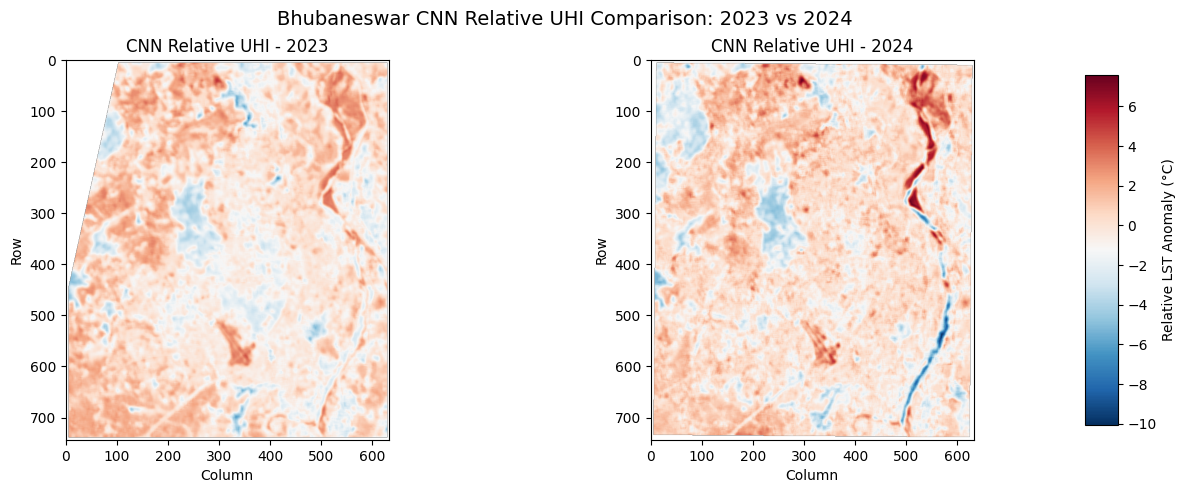

Figure 3 saved successfully!
/content/Figure_3_CNN_UHI_2023_2024.png


In [153]:
# ============================================
# STEP 26: FINAL UHI COMPARISON FIGURE
# COLORBAR OUTSIDE ON THE RIGHT
# ============================================

import rasterio
import matplotlib.pyplot as plt
import numpy as np

# Load 2023 UHI
with rasterio.open(
    "/content/Bhubaneswar_CNN_UHI_2023.tif"
) as src:
    uhi_2023_map = src.read(1)

# Load 2024 UHI
with rasterio.open(
    "/content/Bhubaneswar_CNN_UHI_2024.tif"
) as src:
    uhi_2024_map = src.read(1)

# Mask invalid values
uhi_2023_map = np.ma.masked_invalid(uhi_2023_map)
uhi_2024_map = np.ma.masked_invalid(uhi_2024_map)

# Common color scale
vmin = min(
    uhi_2023_map.min(),
    uhi_2024_map.min()
)

vmax = max(
    uhi_2023_map.max(),
    uhi_2024_map.max()
)

# Create figure
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# -----------------------------
# 2023
# -----------------------------

im1 = axes[0].imshow(
    uhi_2023_map,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title(
    "CNN Relative UHI - 2023"
)

axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")


# -----------------------------
# 2024
# -----------------------------

im2 = axes[1].imshow(
    uhi_2024_map,
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title(
    "CNN Relative UHI - 2024"
)

axes[1].set_xlabel("Column")
axes[1].set_ylabel("Row")


# -----------------------------
# COLORBAR OUTSIDE
# -----------------------------

# Leave space on the right
fig.subplots_adjust(
    left=0.06,
    right=0.87,
    top=0.88,
    bottom=0.12,
    wspace=0.25
)

# Create separate colorbar axis
cbar_ax = fig.add_axes(
    [0.90, 0.15, 0.025, 0.70]
)

cbar = fig.colorbar(
    im2,
    cax=cbar_ax
)

cbar.set_label(
    "Relative LST Anomaly (°C)"
)


# -----------------------------
# Main title
# -----------------------------

fig.suptitle(
    "Bhubaneswar CNN Relative UHI Comparison: 2023 vs 2024",
    fontsize=14
)


# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "/content/Figure_3_CNN_UHI_2023_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully!")
print("/content/Figure_3_CNN_UHI_2023_2024.png")